# AI4I Predictive Maintenance: Exploratory Data Analysis

This notebook explores the UCI AI4I 2020 benchmark used by the project. UCI describes this 10,000-row dataset as synthetic. It has no vibration or pressure features, so neither is used by the trained model. The notebook is exploratory; the reproducible report and figure files are generated by `python scripts/run_eda.py`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'data' / 'ai4i2020.csv').is_file()), Path.cwd())
DATASET_PATH = PROJECT_ROOT / 'data' / 'ai4i2020.csv'
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f'Dataset not found: {DATASET_PATH}. Run python src/download_data.py first.')

data = pd.read_csv(DATASET_PATH)
TARGET = 'Machine failure'
SENSORS = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
print(f'Rows: {len(data):,}; columns: {len(data.columns)}')
display(data[SENSORS].describe().T)
display(data[TARGET].value_counts().rename(index={0: 'No failure', 1: 'Failure'}))

Rows: 10,000; columns: 14


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


Machine failure
No failure    9661
Failure        339
Name: count, dtype: int64

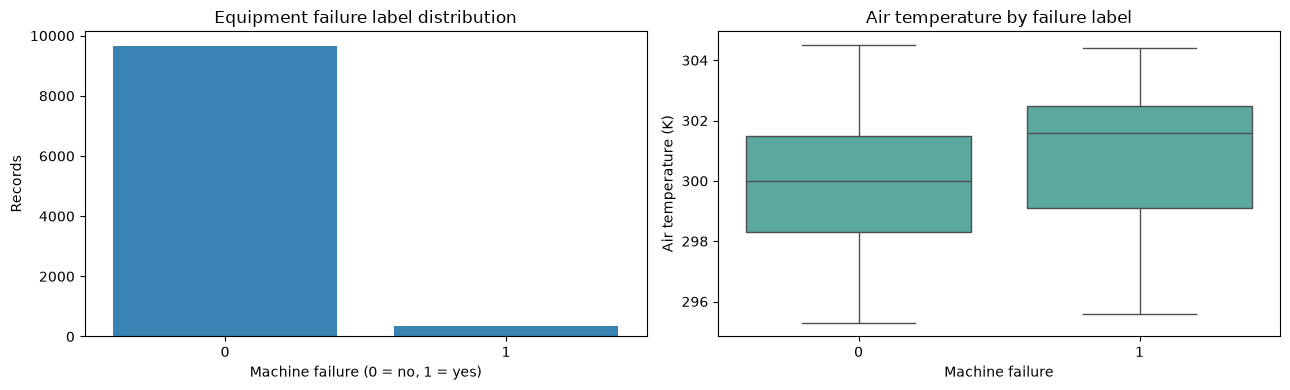

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=data, x=TARGET, ax=axes[0], color='#2387c9')
axes[0].set(title='Equipment failure label distribution', xlabel='Machine failure (0 = no, 1 = yes)', ylabel='Records')
sns.boxplot(data=data, x=TARGET, y='Air temperature [K]', ax=axes[1], color='#50b4a8')
axes[1].set(title='Air temperature by failure label', xlabel='Machine failure', ylabel='Air temperature (K)')
plt.tight_layout()

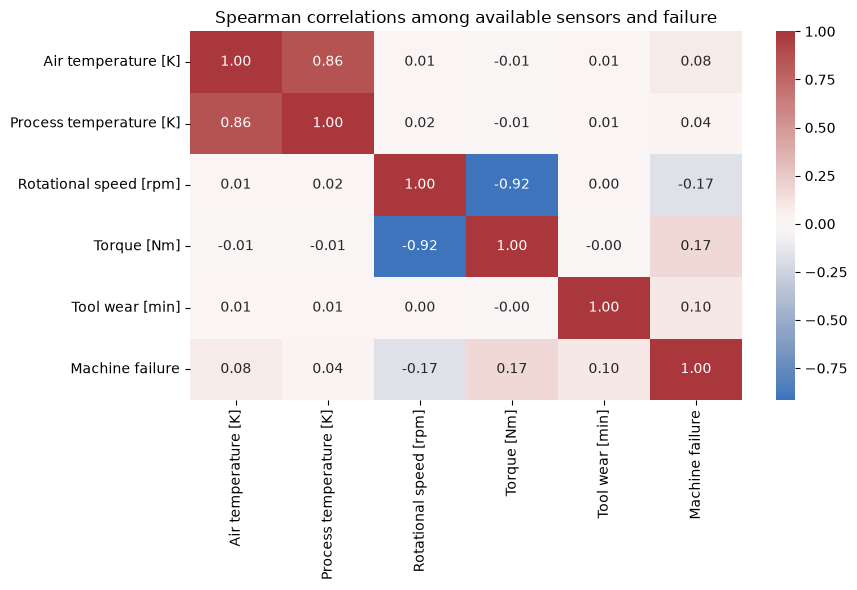

In [4]:
correlation_columns = SENSORS + [TARGET]
plt.figure(figsize=(9, 6))
sns.heatmap(data[correlation_columns].corr(method='spearman'), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Spearman correlations among available sensors and failure')
plt.tight_layout()

,failure rate
Type,
L,0.039167
M,0.027694
H,0.020937


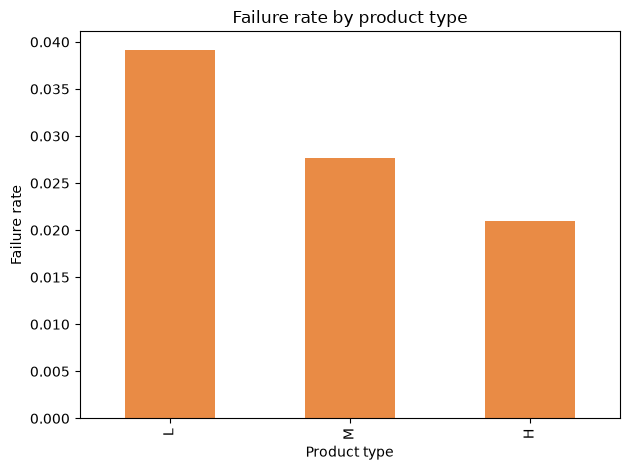

In [5]:
failure_rate_by_type = data.groupby('Type', observed=True)[TARGET].mean().sort_values(ascending=False)
display(failure_rate_by_type.rename('failure rate').to_frame())
failure_rate_by_type.plot(kind='bar', color='#e98b45', title='Failure rate by product type', ylabel='Failure rate', xlabel='Product type', ylim=(0, None))
plt.tight_layout()

## Interpretation

Failures are uncommon, so accuracy alone can look strong even when some failures are missed. The project compares precision, recall, F1, ROC-AUC, average precision, and confusion matrices. These patterns describe this synthetic benchmark and should not be interpreted as causal or as evidence of real factory performance.